In [17]:
suppressMessages(library(Seurat))

In [18]:
in_dir <- "../../Data/LN_rnaseq/Jianbo_Qing_JASN_2026"
out_dir <- "../../results/10_compare_with_public_data/03_Jianbo_Qing_JASN_2026"

if (!dir.exists(out_dir)) {
   dir.create(out_dir, recursive = TRUE)
}

In [19]:
obj <- readRDS(glue::glue("{in_dir}/scedata.rds"))

In [20]:
obj

An object of class Seurat 
31633 features across 44811 samples within 2 assays 
Active assay: integrated (2000 features, 2000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, tsne

In [21]:
colnames(obj@meta.data)

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "percent.mt"             "percent.rb"             "percent.HB"            
 [7] "integrated_snn_res.0.1" "seurat_clusters"        "celltype"              
[10] "group"

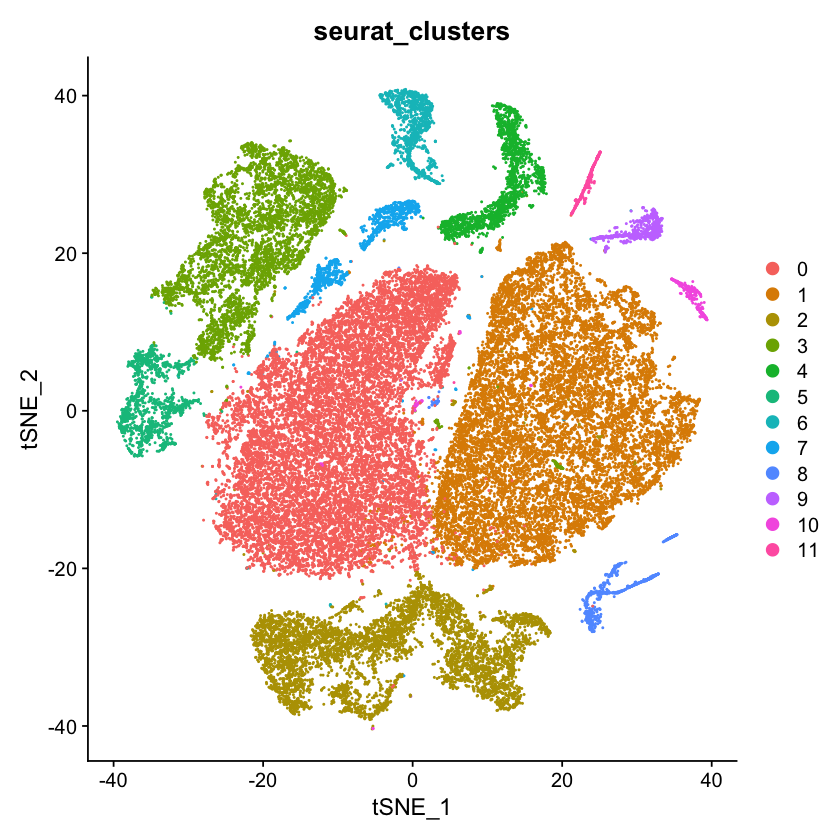

In [22]:
DimPlot(obj, group.by = "seurat_clusters")

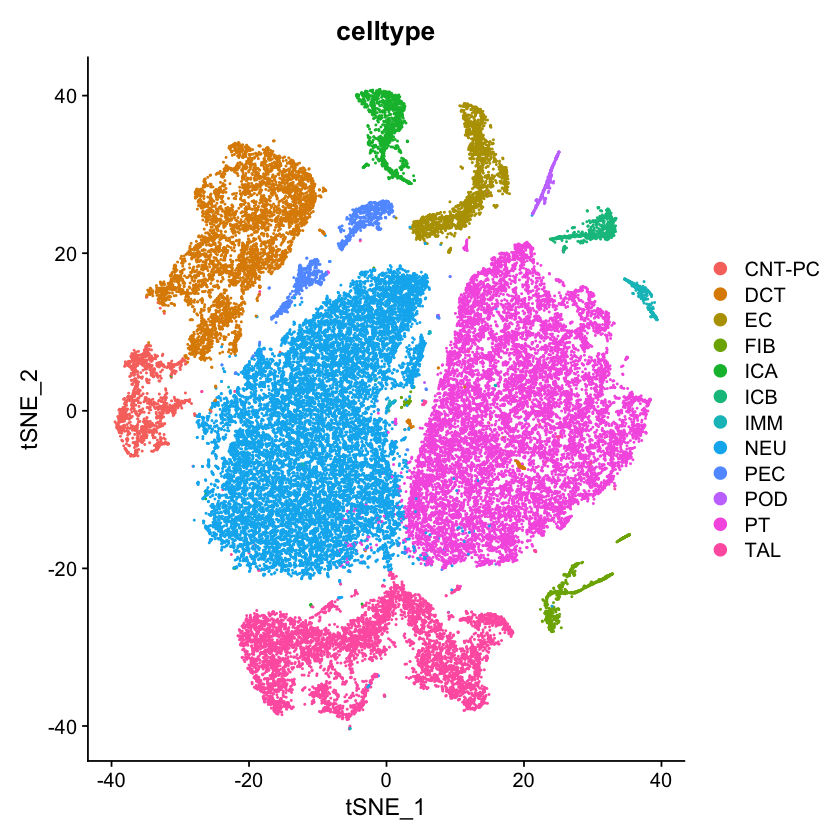

In [23]:
DimPlot(obj, group.by = "celltype")

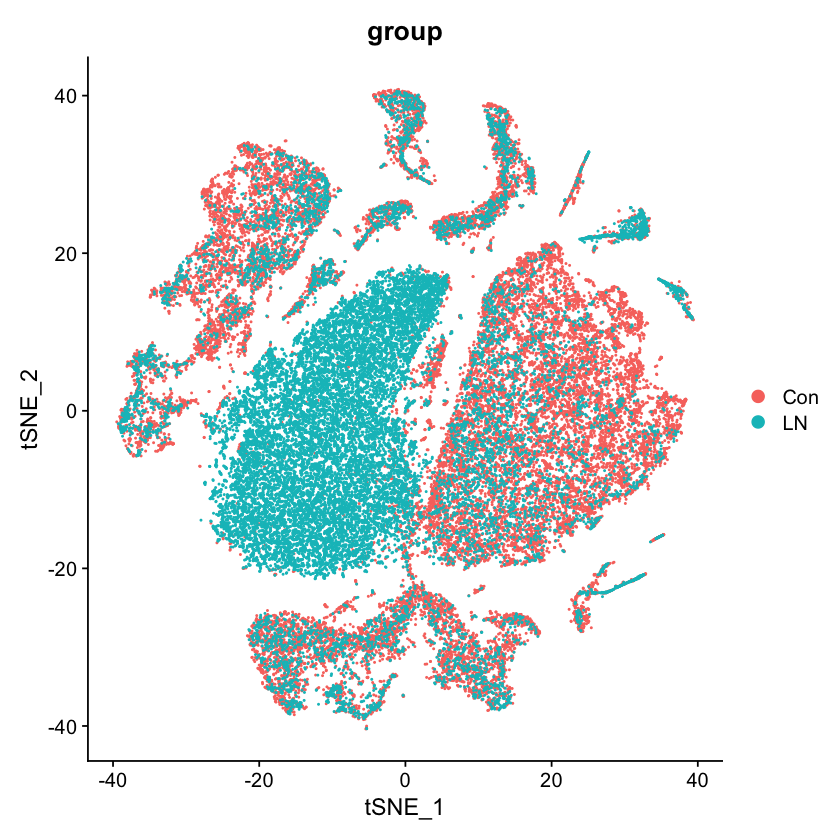

In [24]:
DimPlot(obj, group.by = "group")

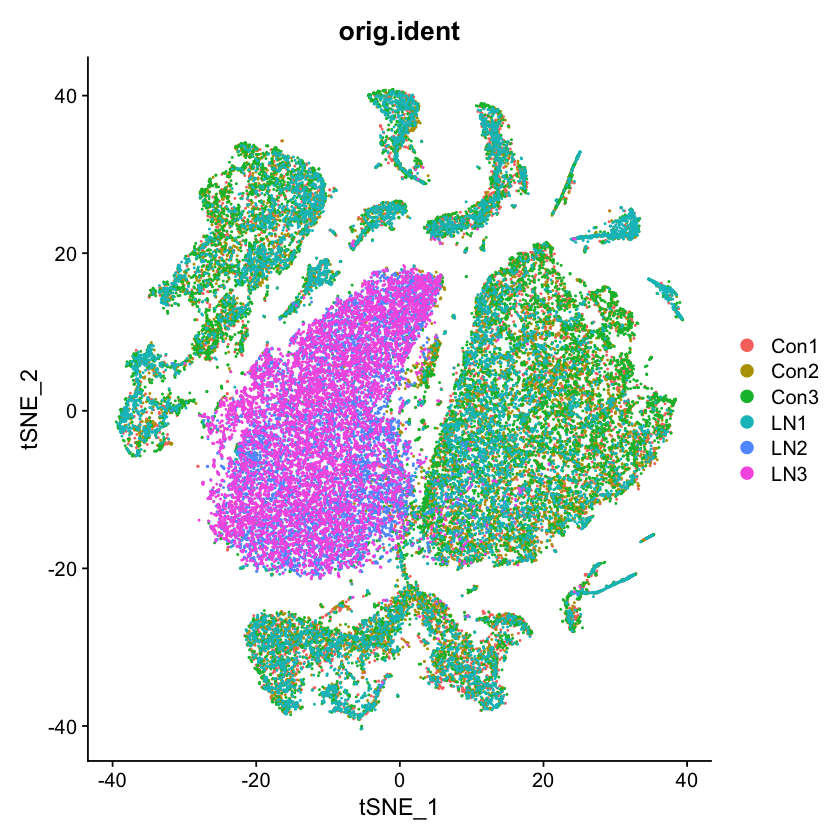

In [25]:
DimPlot(obj, group.by = "orig.ident")

In [26]:
# subset object by LN samples
obj_ln <- subset(obj, group == "LN")

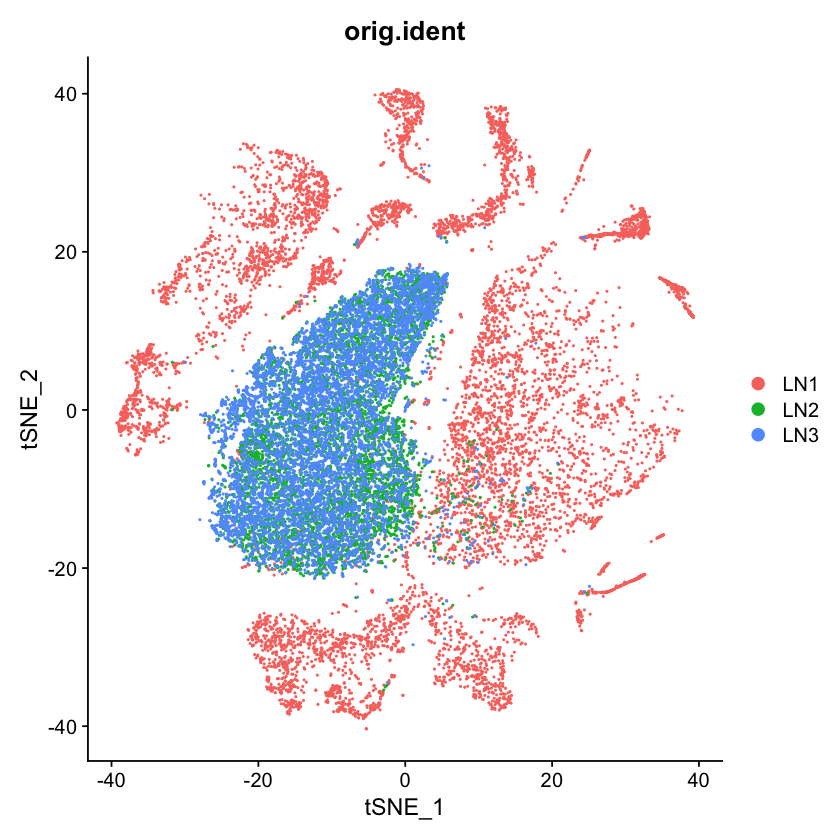

In [27]:
DimPlot(obj_ln, group.by = "orig.ident")

In [28]:
# get pseudo-bulk count matrix for each sample
pbm <- AggregateExpression(obj_ln, 
group.by = "orig.ident", 
return.seurat = TRUE)

Warning message:
“The counts layer for the integrated assay is empty. Skipping assay.”


In [29]:
pbm

An object of class Seurat 
29633 features across 3 samples within 1 assay 
Active assay: RNA (29633 features, 0 variable features)
 2 layers present: counts, data

In [30]:
df <- as.data.frame(pbm@assays$RNA@layers$counts)
rownames(df) <- rownames(pbm)
colnames(df) <- c("LN1", "LN2", "LN3")

In [31]:
head(df)

,LN1,LN2,LN3
,<dbl>,<dbl>,<dbl>
RP11-34P13.7,66,88,100
FO538757.2,652,10,0
AP006222.2,230,77,59
RP4-669L17.10,28,20,6
RP5-857K21.4,1513,519,316
RP11-206L10.4,3,0,4


In [32]:
# save pseudo-bulk count matrix to tsv file
write.table(df,
glue::glue("{out_dir}/pbm.tsv"),
sep = "\t",
quote = FALSE,
col.names = TRUE)